# Прогнозная LTV и проверка на отложенных месяцах

Задача: оценить накопленную выручку на клиента когорты за 24 месяца, когда наблюдается меньше. Когорты те же,
что в исторической LTV: месяц первой платной подписки, с июля 2015 года. Суммы в NTD, без дисконтирования.
Теория: `docs/ltv.md`.

**Метод.** Выручка на клиента в месяце жизни t по всем когортам, наблюдаемым в этом возрасте, образует общий профиль m(t).
Для ненаблюдаемых возрастов профиль продолжается геометрическим хвостом: m(t) = m(T) · ρ^(t − T), где T последний
наблюдаемый возраст, а ρ (ежемесячное сохранение выручки) оценивается по профилю как наклон логарифма выручки от возраста,
не выше 1 (роста не допускаем). Каждая когорта масштабируется на свой уровень: отношение её накопленной выручки к сумме
профиля за тот же срок.

**Проверка.** Берётся прошлая дата «сегодня» (отсечка): прогноз строится только по платежам до неё и сравнивается
с тем, что произошло после. Для сравнения два ориентира: общий профиль без поправки на когорту (проверяет, нужна ли поправка) и наивный прогноз «тот же темп, что уже наблюдался» (слабый: не учитывает, что первый платёж крупнее обычных).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

P = "/workspace/data/processed/"
LAST_MONTH = pd.Timestamp("2017-03-01")  # последний месяц наблюдений
C_FROM, C_TO, MAX_AGE = "2015-07-01", "2016-12-01", 24
INK, BLUE, ORANGE, GRAY = "#2b2f36", "#0072B2", "#E69F00", "#8a8f98"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
for name, file in [("tr", "transactions"), ("anc", "user_anchors")]:
    con.execute(f'''
        CREATE VIEW {name} AS
        SELECT *
        FROM '{P}{file}.parquet'
    ''')

## Данные: выручка когорт по возрастам
Выручка когорты в каждом месяце жизни (по месяцу транзакции) и размер когорты. Клетки за концом наблюдений пустые.

In [2]:
rev = con.sql(f'''
    WITH coh AS (
        SELECT
            msno,
            first_paid_month AS cohort
        FROM anc
        WHERE first_paid_month BETWEEN DATE '{C_FROM}' AND DATE '{C_TO}'
    ),
    pay AS (
        SELECT
            msno,
            date_trunc('month', transaction_date)::DATE AS pay_month,
            sum(actual_amount_paid) AS amount
        FROM tr
        WHERE is_cancel = 0
            AND actual_amount_paid > 0
        GROUP BY msno, 2
    ),
    cohort_size AS (
        SELECT
            cohort,
            count(*) AS size
        FROM coh
        GROUP BY cohort
    )
    SELECT
        coh.cohort,
        date_diff('month', coh.cohort, pay.pay_month) AS age,
        sum(pay.amount) AS revenue,
        any_value(cohort_size.size) AS size
    FROM coh
    JOIN pay USING (msno)
    JOIN cohort_size ON cohort_size.cohort = coh.cohort
    WHERE pay.pay_month >= coh.cohort
        AND date_diff('month', coh.cohort, pay.pay_month) <= {MAX_AGE}
    GROUP BY coh.cohort, 2
''').df()

sizes = rev.groupby("cohort")["size"].first()
ages = list(range(MAX_AGE + 1))


def months_between(a: pd.Timestamp, b: pd.Timestamp) -> int:
    '''Считает число месяцев между двумя датами (первыми днями месяцев).

    Args:
        a (pd.Timestamp): начальная дата.
        b (pd.Timestamp): конечная дата.

    Returns:
        int: b минус a в месяцах.
    '''
    return (b.year - a.year) * 12 + (b.month - a.month)


grid = rev.pivot(index="cohort", columns="age", values="revenue").reindex(index=sizes.index, columns=ages)
seen = np.array([[months_between(c, LAST_MONTH) >= a for a in ages] for c in grid.index])
grid = grid.where(~seen | grid.notna(), 0.0).where(seen)  # нули там, где наблюдали, но платежей не было
pd.DataFrame({"когорт": [len(sizes)], "клиентов": [int(sizes.sum())],
              "наблюдается возрастов у старейшей когорты": [months_between(sizes.index[0], LAST_MONTH)]})

,когорт,клиентов,наблюдается возрастов у старейшей когорты
0,18,875327,20


## Прогноз
Функция `forecast` строит прогноз накопленной выручки на клиента на заданный горизонт по данным до отсечки.

In [3]:
def forecast(cutoff: pd.Timestamp, horizon: int, cohorts, rho_override: float | None = None) -> pd.DataFrame:
    '''Прогнозирует накопленную выручку на клиента когорт на горизонт `horizon` по данным до `cutoff`.

    Args:
        cutoff (pd.Timestamp): последний месяц, доступный для прогноза (первый день месяца).
        horizon (int): горизонт в месяцах жизни (накопление за возрасты 0..horizon).
        cohorts: когорты, для которых строится прогноз.
        rho_override (float | None): если задано, заменяет оценённое ежемесячное сохранение выручки.

    Returns:
        pd.DataFrame: по когорте: наблюдаемый возраст `k`, накопленная выручка к нему `cum_obs`,
            прогноз `pred`, прогноз по общему профилю без поправки на когорту `flat`, наивный прогноз `naive`
            (прежний темп), использованное `rho`, последний возраст профиля `t_obs`.
    '''
    coh = [c for c in cohorts if c <= cutoff]
    k = pd.Series({c: months_between(c, cutoff) for c in coh})
    seen_c = np.array([[a <= k[c] for a in ages] for c in coh])
    rev_c = grid.loc[coh].where(seen_c)
    size_c = sizes.loc[coh]
    denom = (seen_c * size_c.values[:, None]).sum(axis=0)
    profile = pd.Series(rev_c.sum(axis=0).values / np.where(denom > 0, denom, np.nan), index=ages)
    t_obs = int(profile.last_valid_index())

    lo = 3 if t_obs >= 5 else 2
    ts = [t for t in range(lo, t_obs + 1) if profile[t] > 0]
    if rho_override is not None:
        rho = rho_override
    elif len(ts) >= 3:
        slope = np.polyfit(ts, np.log(profile[ts].values), 1)[0]
        rho = min(float(np.exp(slope)), 1.0)
    else:
        rho = 1.0
    anchor = profile[max(lo, t_obs - 2): t_obs + 1].mean()
    m_hat = profile.copy()
    for t in range(t_obs + 1, MAX_AGE + 1):
        m_hat[t] = anchor * rho ** (t - t_obs)

    rows = []
    for c in coh:
        kc = int(k[c])
        cum_obs = float(rev_c.loc[c, : min(kc, horizon)].sum() / sizes[c])
        if kc >= horizon:
            rows.append((c, kc, cum_obs, cum_obs, cum_obs, cum_obs, rho, t_obs))
            continue
        scale = cum_obs / profile[: kc + 1].sum()  # профиль включает возрасты 0..kc
        future = m_hat[kc + 1: horizon + 1].sum()
        rows.append((c, kc, cum_obs, cum_obs + scale * future, cum_obs + future,
                     cum_obs * (horizon + 1) / (kc + 1), rho, t_obs))
    return pd.DataFrame(rows, columns=["cohort", "k", "cum_obs", "pred", "flat", "naive", "rho", "t_obs"]).set_index("cohort")


def actual(horizon: int) -> pd.Series:
    '''Возвращает фактическую накопленную выручку на клиента за возрасты 0..horizon (если она наблюдается полностью).

    Args:
        horizon (int): горизонт в месяцах жизни.

    Returns:
        pd.Series: значение по когорте, NaN для когорт, у которых горизонт не наблюдается.
    '''
    out = grid.loc[:, :horizon].sum(axis=1, min_count=horizon + 1).div(sizes)
    return out

## Проверка на отложенных месяцах
Четыре варианта отсечки и горизонта. Ошибка = (прогноз − факт) / факт, в процентах; смещение это среднее по когортам со знаком,
абсолютная ошибка это среднее модулей. Факт берётся из полных данных и в прогнозе не использовался.

In [4]:
cases = [
    ("отсечка 2015-12, горизонт 12", "2015-12-01", 12),
    ("отсечка 2016-03, горизонт 12", "2016-03-01", 12),
    ("отсечка 2016-06, горизонт 12", "2016-06-01", 12),
    ("отсечка 2015-12, горизонт 18", "2015-12-01", 18),
]
results, rows = {}, []
for label, cut, h in cases:
    cutoff = pd.Timestamp(cut)
    act = actual(h)
    eligible = [c for c in sizes.index if c <= cutoff and act[c] == act[c]]
    f = forecast(cutoff, h, eligible)
    f = f[f.k < h].copy()
    f["actual"] = act[f.index]
    f["err_pct"] = 100 * (f.pred - f.actual) / f.actual
    f["flat_err_pct"] = 100 * (f.flat - f.actual) / f.actual
    f["naive_err_pct"] = 100 * (f.naive - f.actual) / f.actual
    results[label] = f
    rows.append({
        "вариант": label,
        "когорт": len(f),
        "ρ": round(float(f.rho.iloc[0]), 3),
        "прогноз: смещение, %": round(f.err_pct.mean(), 1),
        "прогноз: абс. ошибка, %": round(f.err_pct.abs().mean(), 1),
        "без поправки на когорту: смещение, %": round(f.flat_err_pct.mean(), 1),
        "без поправки на когорту: абс. ошибка, %": round(f.flat_err_pct.abs().mean(), 1),
        "наивный: смещение, %": round(f.naive_err_pct.mean(), 1),
        "наивный: абс. ошибка, %": round(f.naive_err_pct.abs().mean(), 1),
    })
pd.DataFrame(rows)

,вариант,когорт,ρ,"прогноз: смещение, %","прогноз: абс. ошибка, %","без поправки на когорту: смещение, %","без поправки на когорту: абс. ошибка, %","наивный: смещение, %","наивный: абс. ошибка, %"
0,"отсечка 2015-12, горизонт 12",6,0.981,-0.8,3.8,-1.3,1.7,90.3,90.3
1,"отсечка 2016-03, горизонт 12",9,0.993,0.2,5.2,2.3,2.4,51.9,51.9
2,"отсечка 2016-06, горизонт 12",9,0.980,-3.3,3.3,-2.3,2.3,14.9,14.9
3,"отсечка 2015-12, горизонт 18",3,0.981,-8.4,8.4,-8.5,8.5,41.8,41.8


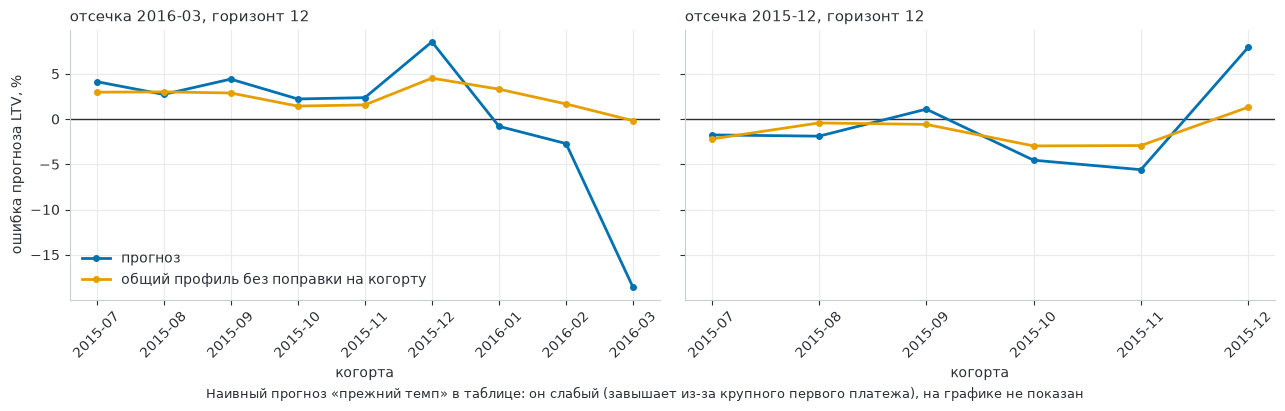

,наблюдалось месяцев,накоплено к отсечке,прогноз,факт,"ошибка, %"
cohort,,,,,
2015-07-01,8,996.9,1330.2,1277.4,4.1
2015-08-01,7,873.8,1259.6,1226.2,2.7
2015-09-01,6,829.6,1322.8,1266.9,4.4
2015-10-01,5,722.1,1293.3,1265.2,2.2
2015-11-01,4,644.2,1290.9,1261.1,2.4
2015-12-01,3,594.1,1360.1,1253.2,8.5
2016-01-01,2,445.9,1191.9,1201.6,-0.8
2016-02-01,1,369.2,1192.9,1226.2,-2.7
2016-03-01,0,231.7,980.0,1204.2,-18.6


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, label in zip(axes, ["отсечка 2016-03, горизонт 12", "отсечка 2015-12, горизонт 12"]):
    f = results[label]
    x = f.index.strftime("%Y-%m")
    ax.axhline(0, color=INK, lw=1)
    ax.plot(x, f.err_pct, color=BLUE, lw=2, marker="o", ms=4, label="прогноз")
    ax.plot(x, f.flat_err_pct, color=ORANGE, lw=2, marker="o", ms=4, label="общий профиль без поправки на когорту")
    ax.set_title(label, loc="left", fontsize=11)
    ax.set_xlabel("когорта")
    ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("ошибка прогноза LTV, %")
axes[0].legend(frameon=False, loc="best")
plt.suptitle("Наивный прогноз «прежний темп» в таблице: он слабый (завышает из-за крупного первого платежа), на графике не показан", fontsize=9, y=0.02)
plt.tight_layout()
plt.show()
results["отсечка 2016-03, горизонт 12"][["k", "cum_obs", "pred", "actual", "err_pct"]].round(1).rename(
    columns={"k": "наблюдалось месяцев", "cum_obs": "накоплено к отсечке", "pred": "прогноз", "actual": "факт", "err_pct": "ошибка, %"})

## Прогноз LTV на 24 месяца по всем данным
Отсечка 2017-03. Сценарии ρ: оценённый по данным (не выше 1), пессимистичный 0,98 и без убыли 1,0. Для когорт 2015-07 .. 2016-12.

In [6]:
cohorts = list(sizes.index)
base = forecast(LAST_MONTH, 24, cohorts)
low = forecast(LAST_MONTH, 24, cohorts, rho_override=0.98)
high = forecast(LAST_MONTH, 24, cohorts, rho_override=1.0)
base12 = forecast(LAST_MONTH, 12, cohorts)
final = pd.DataFrame({
    "наблюдалось месяцев": base.k,
    "накоплено к концу данных": base.cum_obs.round(0),
    "LTV 12 мес": base12.pred.round(0),
    "LTV 24 мес, ρ=0,98": low.pred.round(0),
    "LTV 24 мес, ρ по данным": base.pred.round(0),
    "LTV 24 мес, ρ=1": high.pred.round(0),
    "LTV 24 мес, без поправки на когорту": base.flat.round(0),
})
final.index = final.index.strftime("%Y-%m")
print("ρ по данным:", round(float(base.rho.iloc[0]), 3), " последний возраст профиля:", int(base.t_obs.iloc[0]))
diff = 100 * (base.pred - base.flat).abs() / base.flat
print("расхождение прогноза с поправкой и без, % (среднее / наибольшее):", round(diff.mean(), 1), "/", round(diff.max(), 1))
final

ρ по данным: 0.996  последний возраст профиля: 20
расхождение прогноза с поправкой и без, % (среднее / наибольшее): 0.9 / 3.7


,наблюдалось месяцев,накоплено к концу данных,LTV 12 мес,"LTV 24 мес, ρ=0,98","LTV 24 мес, ρ по данным","LTV 24 мес, ρ=1","LTV 24 мес, без поправки на когорту"
cohort,,,,,,,
2015-07,20,1964.0,1277.0,2253.0,2265.0,2267.0,2257.0
2015-08,19,1809.0,1226.0,2164.0,2175.0,2178.0,2181.0
2015-09,18,1791.0,1267.0,2229.0,2241.0,2244.0,2234.0
2015-10,17,1725.0,1265.0,2237.0,2249.0,2252.0,2240.0
2015-11,16,1648.0,1261.0,2232.0,2244.0,2247.0,2234.0
2015-12,15,1570.0,1253.0,2229.0,2241.0,2244.0,2231.0
2016-01,14,1407.0,1202.0,2108.0,2119.0,2122.0,2149.0
2016-02,13,1328.0,1226.0,2156.0,2168.0,2170.0,2183.0
2016-03,12,1204.0,1204.0,2129.0,2140.0,2143.0,2170.0


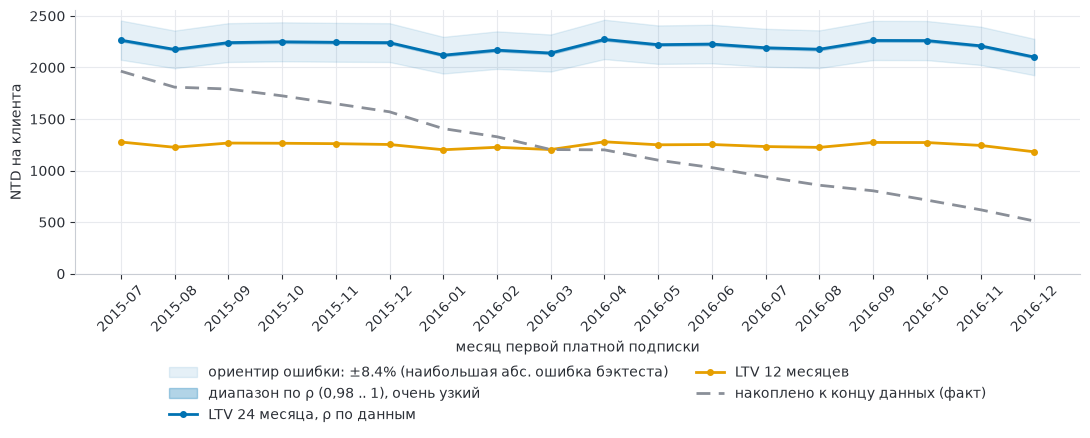

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = final.index
ref = max(r["прогноз: абс. ошибка, %"] for r in rows)
base24 = final["LTV 24 мес, ρ по данным"]
ax.fill_between(x, base24 * (1 - ref / 100), base24 * (1 + ref / 100), color=BLUE, alpha=0.10,
                label=f"ориентир ошибки: ±{ref:.1f}% (наибольшая абс. ошибка бэктеста)")
ax.fill_between(x, final["LTV 24 мес, ρ=0,98"], final["LTV 24 мес, ρ=1"], color=BLUE, alpha=0.30, label="диапазон по ρ (0,98 .. 1), очень узкий")
ax.plot(x, final["LTV 24 мес, ρ по данным"], color=BLUE, lw=2, marker="o", ms=4, label="LTV 24 месяца, ρ по данным")
ax.plot(x, final["LTV 12 мес"], color=ORANGE, lw=2, marker="o", ms=4, label="LTV 12 месяцев")
ax.plot(x, final["накоплено к концу данных"], color=GRAY, lw=2, ls=(0, (5, 3)), label="накоплено к концу данных (факт)")
ax.set_xlabel("месяц первой платной подписки")
ax.set_ylabel("NTD на клиента")
ax.set_ylim(0, None)
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
plt.tight_layout()
plt.show()

## Выводы
- **Прогноз.** LTV за 24 месяца для когорт 2015-07 .. 2016-12 от 2101 до 2272 NTD на клиента, это примерно в 1,7–1,8 раза больше LTV за 12 месяцев (1182–1279 NTD). Когорты между собой различаются слабо.
- **Проверка на отложенных месяцах.** На 12 месяцев вперёд средняя абсолютная ошибка 3–5% (смещение от −3,3% до +0,2%), на 18 месяцев 8,4% (прогноз занижает на 8,4%, всего 3 когорты). Факт в прогнозе не использовался.
- **Поправка на уровень когорты не нужна.** Общий профиль без поправки не хуже: ошибка 1,7–2,4% против 3,3–5,2% на горизонте 12 месяцев, на горизонте 18 одинаково 8,5%. Итоговые прогнозы двух способов расходятся в среднем на 0,9% (наибольшее расхождение 3,7%). Поправка по одному наблюдаемому месяцу ненадёжна: у когорты, известной только по месяцу 0, ошибка −18,6%, потому что первый платёж сильно зависит от выбранного тарифа.
- **Наивный прогноз «прежний темп»** завышает на 15–90%: он не учитывает, что первый платёж крупнее обычных. Это слабый ориентир, он нужен только как нижняя планка.
- **Что прогноз не гарантирует.** 24 месяца дальше проверенного горизонта (проверено до 18 месяцев на трёх когортах). Для когорт 2016 года прогноз опирается на профиль, снятый с более ранних когорт, и предполагает такое же поведение. Прогноз на 18 месяцев занижал факт, поэтому прогноз на 24 месяца, вероятно, консервативен (гипотеза: кривая ускоряется после 12 месяцев из-за продлений длинных тарифов).
- **Диапазон по ρ очень узкий:** ρ влияет только на возрасты старше 20 месяцев. Реалистичный ориентир неопределённости это ошибка бэктеста, около ±8,4%.
- **Условия:** тайваньские доллары, без дисконтирования, выручка, а не прибыль, платёж относится к месяцу транзакции.